# Filtro de cámara sobre D-Fire y re-entrenamiento

**Proyecto Final de Ingeniería en Electrónica — FaCENA-UNNE**
(Red de sensores LoRa para detección temprana de incendios)

La red v3 aprendió con fotos web de D-Fire, pero en el nodo ve lo que entrega el **OV5640**:
otro balance de blancos, altas luces quemadas, más saturación, más ruido y color RGB565. Todavía
no hay suficientes capturas reales con fuego y humo para hacer un fine-tuning con ellas
(`13_fine_tuning_camara.ipynb`). Lo que sí se puede hacer es **ensuciar D-Fire para que se vea
como la cámara** y ajustar la red con eso: tiene miles de incendios etiquetados. Es
**adaptación de dominio por aumento**: se simula el sensor sobre el dominio fuente (D-Fire)
hasta que sus estadísticas se parezcan a las del dominio destino (las capturas).

El filtro es `CamaraOV` de `modulos/camara_ov.py`, un aumento **aleatorio**: cada imagen pasa
por la cadena óptica → sensor → ISP del OV5640:

velo magenta → viñeteo → balance de blancos → exposición (quema altas luces) → **noche** (20 %:
escena oscura, la llama queda) → gamma (contraste) → saturación → nitidez/desenfoque → ruido
(crece con la señal) → nivel de negro → RGB565,

con parámetros sorteados dentro de rangos medidos sobre las capturas reales de `data/capturas/`
(QVGA/VGA/UXGA, JPEG y BMP, día y noche, con y sin fuego).
Reemplaza a `ColorRGB565` del notebook 4 (el RGB565 es el último paso de la cadena).

| Entra | Sale (en `salidas/modelos/v{VERSION}/{fecha-hora}/`) |
|---|---|
| el `cnn_fuego_3clases_*.keras` más reciente de `v{VERSION_BASE}/`, D-Fire y las capturas de `data/capturas/` (sólo para medir) | `cnn_fuego_3clases_cam_*.keras`, `historia.csv`, `curvas.png`, `filtro.png` |

**Después de este notebook:** `5_cuantizacion.ipynb` con `VERSION = 4` (cuantiza este modelo a
`v4/cuantizacion/`) y, cuando haya capturas etiquetadas, `13_fine_tuning_camara.ipynb` con
`VERSION = 4`.

**Recorrido:** medición cámara vs D-Fire → el filtro y su verificación → ajuste fino con D-Fire
filtrado → evaluación base vs nuevo.

## 0. Entorno

In [1]:
# Precarga de librerías CUDA + sonda de GPU: misma razón y mismo código que el notebook 4
# (cuDNN 9.26 de TF 2.21 no tiene kernels para la GTX 1050; sin esto cae a CPU o muere).
import ctypes, glob, os, site, subprocess, sys

for _lib in glob.glob(os.path.join(site.getsitepackages()[0], "nvidia", "*", "lib", "*.so*")):
    try:
        ctypes.CDLL(_lib, mode=ctypes.RTLD_GLOBAL)
    except OSError:
        pass

_SONDA = (
    "import ctypes,glob,os,site\n"
    "for l in glob.glob(os.path.join(site.getsitepackages()[0],'nvidia','*','lib','*.so*')):\n"
    "    try: ctypes.CDLL(l, mode=ctypes.RTLD_GLOBAL)\n"
    "    except OSError: pass\n"
    "import tensorflow as tf\n"
    "assert tf.config.list_physical_devices('GPU')\n"
    "with tf.device('/GPU:0'):\n"
    "    tf.nn.conv2d(tf.zeros([1,32,32,3]), tf.zeros([3,3,3,8]), 1, 'SAME').numpy()\n"
)
_sonda = subprocess.run([sys.executable, "-c", _SONDA], capture_output=True,
                        env={**os.environ, "TF_CPP_MIN_LOG_LEVEL": "3"})
if _sonda.returncode != 0:
    os.environ["CUDA_VISIBLE_DEVICES"] = ""
    print("GPU descartada, se entrena en CPU:", (_sonda.stderr.decode().strip().splitlines() or ["sin GPU"])[-1][:160])
else:
    print("GPU utilizable para convoluciones.")

GPU utilizable para convoluciones.


In [2]:
import csv
import json
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import average_precision_score, classification_report, f1_score
from tensorflow import keras
from tensorflow.keras import layers

MODULOS = Path("../modulos") if Path("../modulos").exists() else Path("modulos")
SALIDAS = MODULOS.parent / "salidas"
sys.path.insert(0, str(MODULOS.resolve()))
for _m in ("dfire", "camara_ov"):
    sys.modules.pop(_m, None)
from camara_ov import CamaraOV, estadisticas, tabla
from dfire import CATEGORIAS, armar_ds, categoria, indexar, leer_imagen, particion, sin_gemelo

VERSION_BASE = 3       # modelo de partida (receta 2, notebook 4)
VERSION = 4            # = v3 + ajuste fino con D-Fire filtrado por CamaraOV (este notebook)
SEED = 42
BATCH_SIZE = 32
keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

DIR_CAPTURAS = (MODULOS.parent / "data/capturas").resolve()
DATA_DIR = MODULOS.parent / "data/datasets/sayedgamal99/smoke-fire-detection-yolo/versions/1/data"
assert DATA_DIR.exists(), f"no está D-Fire en {DATA_DIR}: correr antes 4.red_entrenada.ipynb"

INICIO = datetime.now(ZoneInfo("America/Argentina/Buenos_Aires"))
CORRIDA = SALIDAS / "modelos" / f"v{VERSION}" / INICIO.strftime("%Y%m%d-%H%M")
CORRIDA.mkdir(parents=True, exist_ok=True)
print("TensorFlow:", tf.__version__, "| salidas en", CORRIDA)

I0000 00:00:1792438504.215776  127637 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0 | salidas en ../salidas/modelos/v4/20261019-1635


## 1. Cámara vs D-Fire

`estadisticas()` resume "cómo se ve" un conjunto de imágenes: balance de color (R/G, B/G),
saturación, percentiles de luminancia, ruido de alta frecuencia y fracción de píxeles quemados.
Las capturas son todas las de `data/capturas/`: BMP QVGA de la estación (RGB565 sin pérdida, la
entrada exacta de la red) y JPEG del visor (`frame_*.jpg`, QVGA, VGA y UXGA); los mosaicos de
análisis de esas carpetas se excluyen. Todas se llevan a la entrada de la red con `leer_imagen`,
igual que D-Fire. Se separan en **día** y **noche** (mediana de luminancia < 30): la noche es otro
régimen (90 % de píxeles negros, el fuego como un punto) y promediada con el día no se ve.

Salvedades:

- **Las capturas son pocas escenas** (patio con pasto, muro, árbol). Parte del verde de R/G es la
  escena, no el sensor: por eso los rangos del filtro incluyen "neutro" y no sólo la media medida.
- **Los JPEG (calidad 70) bajan el ruido medido** y no son lo que ve el nodo (RGB565 crudo): el
  ruido se calibra con las BMP.
- **El bracketing EV −2/−1/0 de la estación no da tres brillos ordenados**: medido el 2026-10-18,
  la toma "EV −2" sale *más* clara que la "EV −1" (123 vs 101 de brillo medio, ordenadas en sólo
  29 de 112 tripletes) aunque `exp16` sí se escala (84/168/336). Parece que el frame llega con la
  exposición anterior. Por eso el rango de exposición del filtro sale de la distribución total y
  no de la columna `ev` del CSV. Revisar en el firmware (descartar 1-2 frames tras cambiar la
  exposición).

In [3]:
candidatos = sorted((SALIDAS / "modelos" / f"v{VERSION_BASE}").glob("*/cnn_fuego_3clases_*.keras"),
                    key=lambda p: p.stat().st_mtime)
assert candidatos, f"no hay modelo v{VERSION_BASE} en salidas/modelos/v{VERSION_BASE}/"
RUTA_BASE = candidatos[-1]
modelo_ref = keras.models.load_model(RUTA_BASE)        # queda intacto: el "antes"
modelo_base = keras.models.load_model(RUTA_BASE)       # el que se ajusta
TAM = tuple(modelo_base.input_shape[1:3])
print(f"base: {RUTA_BASE.relative_to(SALIDAS)}  entrada {TAM}")

ARCHIVOS, ETIQUETAS, SPLITS = indexar(DATA_DIR)
CAT = categoria(ETIQUETAS)
particiones = particion(SPLITS, SEED)
idx_train, idx_val, idx_test = (particiones[s] for s in ("train", "val", "test"))
val_limpio = idx_val[sin_gemelo(ARCHIVOS[idx_train], ARCHIVOS[idx_val])]
test_limpio = idx_test[sin_gemelo(ARCHIVOS[idx_train], ARCHIVOS[idx_test])]
print(f"D-Fire: train {len(idx_train)}, val sin gemelos {len(val_limpio)}, prueba sin gemelos {len(test_limpio)}")

# Sólo frames: las BMP de la estación y los frame_*.jpg del visor (no mosaicos ni composiciones).
capturas = sorted(p for p in DIR_CAPTURAS.rglob("*")
                  if p.suffix.lower() == ".bmp" or (p.suffix.lower() == ".jpg" and p.name.startswith("frame_")))
assert capturas, f"no hay capturas en {DIR_CAPTURAS}"
print(f"capturas: {len(capturas)} en {DIR_CAPTURAS}")


def leer(rutas):
    return np.stack([leer_imagen(str(r), TAM).numpy() for r in rutas]).astype(np.float32)


muestra_cap = leer(capturas[::max(1, len(capturas) // 400)])
noche_cap = np.median(muestra_cap.mean(-1), axis=(1, 2)) < 30
print(f"muestra de capturas: {len(muestra_cap)} ({noche_cap.sum()} de noche)")
muestra_df = leer(ARCHIVOS[idx_train[::max(1, len(idx_train) // 400)]])
filtro = CamaraOV(1.0)
tf.random.set_seed(SEED)
muestra_filtrada = np.concatenate([filtro(muestra_df[i:i + 50], training=True).numpy()
                                   for i in range(0, len(muestra_df), 50)])
noche_filt = np.median(muestra_filtrada.mean(-1), axis=(1, 2)) < 30
tabla({"cámara día": estadisticas(muestra_cap[~noche_cap]), "cámara noche": estadisticas(muestra_cap[noche_cap]),
       "D-Fire": estadisticas(muestra_df),
       "filtrado día": estadisticas(muestra_filtrada[~noche_filt]),
       "filtrado noche": estadisticas(muestra_filtrada[noche_filt])})

I0000 00:00:1792438506.906741  127637 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3488 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1050, pci bus id: 0000:01:00.0, compute capability: 6.1


base: modelos/v3/20260928-1357/cnn_fuego_3clases_v3_epochs_124_image_size_320x240.keras  entrada (240, 320)
D-Fire: train 14122, val sin gemelos 2399, prueba sin gemelos 3320
capturas: 1443 en /home/gabi/Documentos/FaCENA/proyecto_final/Desarrollo/Pruebas/data/capturas


/home/gabi/Documentos/FaCENA/proyecto_final/Desarrollo/Pruebas/modulos/camara_ov.py:119: RuntimeWarning: invalid value encountered in divide
  return {"R/G": float(np.mean(m[:, 0] / m[:, 1])), "B/G": float(np.mean(m[:, 2] / m[:, 1])),


medida                cámara          D-Fire D-Fire filtrado
R/G                      nan           1.098           0.938
B/G                      nan           0.987           0.865
saturación             0.421           0.303           0.391
L p10                 23.712          32.941          38.408
L p50                 57.121          83.133          98.377
L p90                145.348         169.793         187.619
L p99                170.656         210.435         223.050
ruido HF               2.865           1.802           5.155
clip>250               0.077           0.024           0.118


**Qué mirar:** "filtrado día" tiene que quedar más cerca de "cámara día" que "D-Fire" en todas
las filas, y "filtrado noche" cerca de "cámara noche" (sobre todo `L p50` y `L<20`). Si alguna se
pasa o no llega, el rango a tocar está arriba de todo en `modulos/camara_ov.py` (constantes
`EXPOSICION`, `GAMMA`, `NEGRO`, `NOCHE`, `RUIDO`, …); su docstring tiene la tabla de referencia
del 2026-10-20 (D-Fire / cámara / filtro: p10 31 / 23-28 / 25, p50 81 / 68 / 77, quemados
2,9 % / 10 % / 13 %, ruido 1,7 / 2,6-4,0 / 3,0; noche p50 10 / 7, L<20 90 % / 80 %).

La figura de abajo muestra **cada efecto por separado y exagerado** sobre una misma foto con fuego
(para ver qué hace cada uno) y después sorteos del filtro completo, que es lo que ve la red.


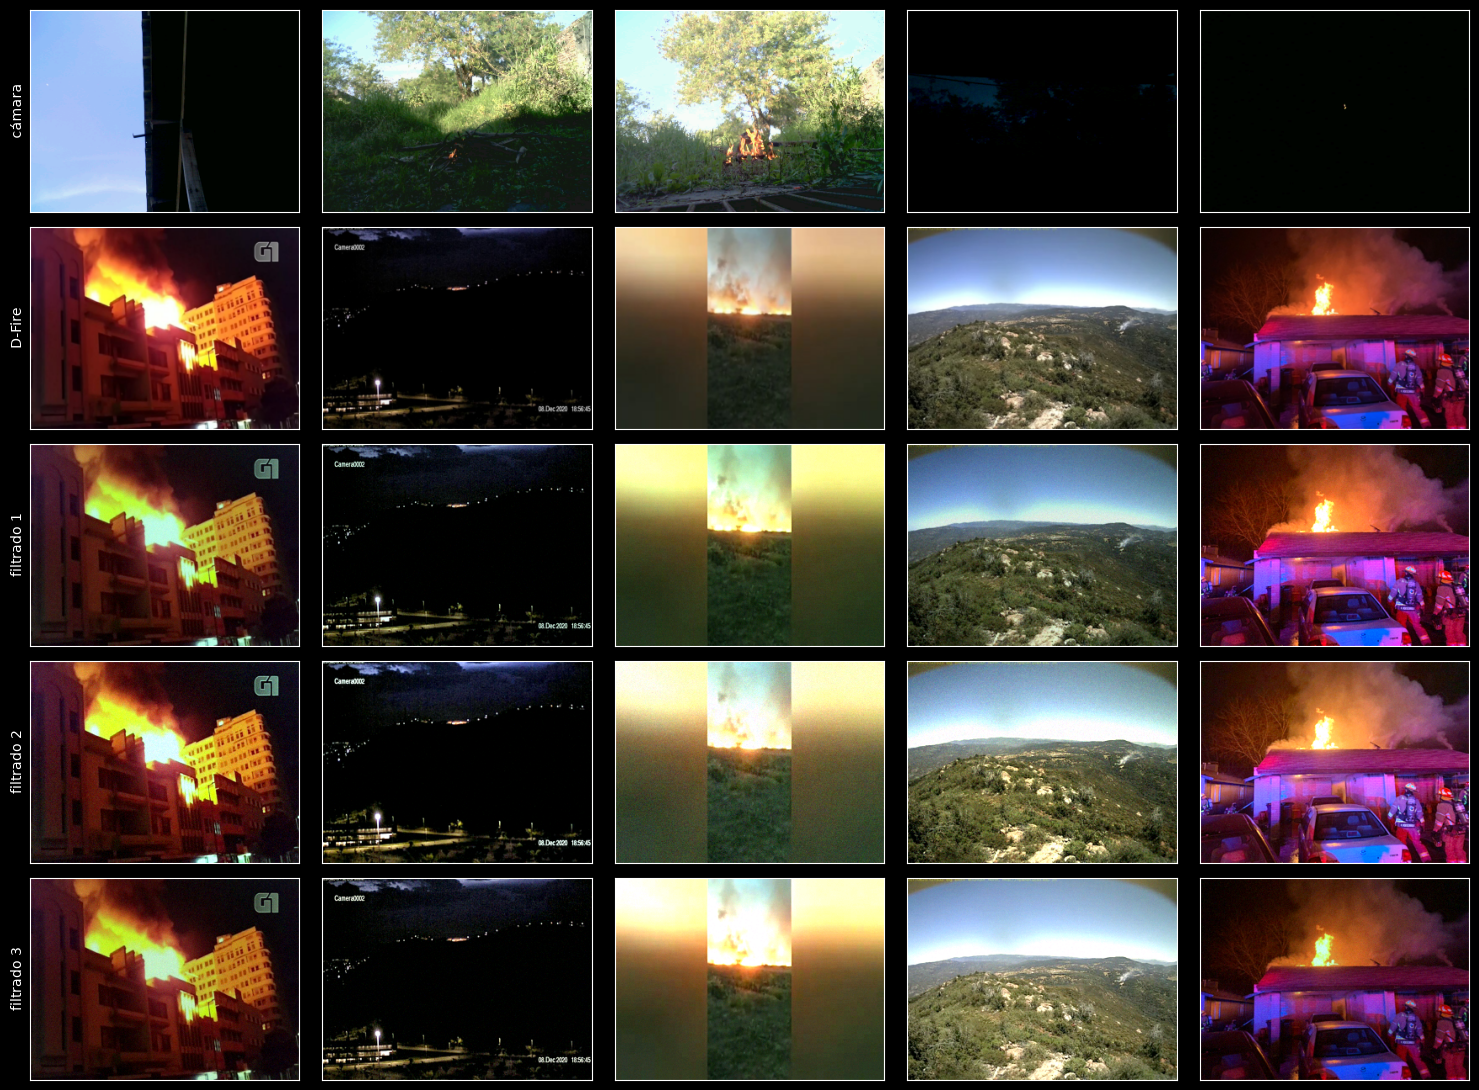

In [4]:
# Catálogo: cada efecto solo y a fondo sobre la misma imagen con fuego (para ver qué hace).
import camara_ov as cam
uno = lambda v: tf.constant(v, tf.float32, shape=(1, 1, 1, 1))
con_fuego = np.flatnonzero(CAT[idx_train[::max(1, len(idx_train) // 400)]] == 2)
base = muestra_df[con_fuego[0] if len(con_fuego) else 0][None] / 255.0
efectos = {
    "D-Fire": base,
    "velo magenta": cam.velo(base, uno(0.5), uno(0.1), uno(0.3), uno(0.5), uno(0.7)),
    "viñeteo": cam.vineteo(base, uno(0.45)),
    "exposición ×1,6": tf.clip_by_value(base * 1.6, 0, 1),
    "gamma 1,6": base ** 1.6,
    "noche ×0,15": cam.noche(base, uno(0.15)),
    "desenfoque": tf.nn.depthwise_conv2d(tf.pad(base, [[0, 0], [1, 1], [1, 1], [0, 0]], "REFLECT"),
                                         filtro.desenfoque, [1, 1, 1, 1], "VALID"),
    "ruido σ=6 + RGB565": cam.a_rgb565(tf.clip_by_value(base + tf.random.normal(base.shape) * 6 / 255, 0, 1) * 255) / 255,
}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (titulo, img) in zip(axes.flat, efectos.items()):
    ax.imshow(np.clip(np.asarray(img)[0], 0, 1)); ax.set_title(titulo); ax.axis("off")
plt.tight_layout()
plt.show()

# Filas 1-2: capturas reales de día y de noche (referencia). Abajo: D-Fire original y tres sorteos del filtro.
n = 5
dia, noc = muestra_cap[~noche_cap], muestra_cap[noche_cap]
fig, axes = plt.subplots(6, n, figsize=(3 * n, 13))
for j in range(n):
    axes[0, j].imshow(dia[j * len(dia) // n].astype("uint8"))
    if len(noc):
        axes[1, j].imshow(noc[j * len(noc) // n].astype("uint8"))
    original = muestra_df[j * 37 % len(muestra_df)]
    axes[2, j].imshow(original.astype("uint8"))
    for k in range(3):
        axes[3 + k, j].imshow(filtro(original[None], training=True)[0].numpy().astype("uint8"))
for ax, titulo in zip(axes[:, 0], ["cámara día", "cámara noche", "D-Fire", "filtrado 1", "filtrado 2", "filtrado 3"]):
    ax.set_ylabel(titulo)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(CORRIDA / "filtro.png", dpi=90)
plt.show()


## 2. Ajuste fino con D-Fire filtrado

Se parte de los pesos v3 (no de cero: ya saben qué es humo y fuego, lo que cambia es cómo se
ve) y se entrena con **todo el train de D-Fire**, con el aumento de la receta 2 pero
`CamaraOV(P_CAMARA)` en el lugar de `ColorRGB565`, y `RandomZoom` que también **aleja** hasta
50 % (el fuego lejano de las capturas ocupa pocos píxeles; D-Fire casi siempre lo tiene cerca). `P_CAMARA` alto porque el nodo sólo va a ver
la cámara; no 1 para que la red no dependa de los artefactos del filtro.

- **lr 3e-5**, backbone suelto con BN congeladas (como la etapa 2 del notebook 4).
- **Validación = D-Fire validación sin gemelos, filtrada una sola vez** (`.cache()` después del
  filtro: todas las épocas ven las mismas imágenes filtradas). `EarlyStopping` sigue la PR-AUC de
  la alerta `1 − P(normal)` sobre ella, igual que la receta 2.
- **Volver a entrenar desde cero** en lugar de ajustar: correr el notebook 4 con `CamaraOV` en el
  lugar de `ColorRGB565`. Cuesta ~1 h de T4; probar primero esto.

In [5]:
P_CAMARA = 0.8
EPOCAS = 40            # tope: decide EarlyStopping
LR = 3e-5

aumento_datos = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(1 / 24),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom((-0.15, 0.5)),       # >0 aleja: fuegos chicos, como a distancia
    layers.RandomContrast(0.10),
    layers.RandomBrightness(0.15),
    layers.RandomErasing(factor=0.5, scale=(0.02, 0.08)),
    CamaraOV(P_CAMARA, name="camara_ov"),       # último, como en la cámara
], name="aumento_datos")

train_ds = armar_ds(ARCHIVOS[idx_train], CAT[idx_train], BATCH_SIZE, mezclar=True, seed=SEED, tam=TAM)
filtro_val = CamaraOV(1.0)
val_cam_ds = (armar_ds(ARCHIVOS[val_limpio], CAT[val_limpio], BATCH_SIZE, tam=TAM)
              .map(lambda x, y: (filtro_val(x, training=True), y)).cache())
for _ in val_cam_ds:       # llena el caché: desde acá el filtrado de validación queda fijo
    pass

conteos = np.bincount(CAT[idx_train], minlength=len(CATEGORIAS))
PESOS_CLASE = {c: len(idx_train) / (len(CATEGORIAS) * n) for c, n in enumerate(conteos)}


class PRAUCAlerta(keras.callbacks.Callback):
    '''PR-AUC de 1 - P(normal) sobre la validación filtrada; deja `val_pr_auc` en logs.'''
    def on_epoch_end(self, epoca, logs=None):
        p = 1 - modelo_base.predict(val_cam_ds, verbose=0)[:, 0]
        logs["val_pr_auc"] = float(average_precision_score(CAT[val_limpio] > 0, p))


modelo_base.get_layer("mobilenet").trainable = True
for capa in modelo_base.get_layer("mobilenet").layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False

entrada_train = keras.Input(shape=(*TAM, 3), name="entrada_train")
modelo_train = keras.Model(entrada_train, modelo_base(aumento_datos(entrada_train)), name="cnn_fuego_cam")
modelo_train.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=LR),
    loss="sparse_categorical_crossentropy",
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)
historia = modelo_train.fit(
    train_ds, validation_data=val_cam_ds, epochs=EPOCAS, class_weight=PESOS_CLASE, verbose=2,
    callbacks=[
        PRAUCAlerta(),       # primero: deja val_pr_auc para EarlyStopping
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                          min_lr=1e-7, verbose=1),
    ],
).history

Epoch 1/40


/home/gabi/Documentos/FaCENA/proyecto_final/Desarrollo/Pruebas/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792438770.187553  128114 cuda_dnn.cc:461] Loaded cuDNN version 90800
I0000 00:00:1792438867.594873  128115 service.cc:153] XLA service 0x62565750 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792438867.594894  128115 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1050, Compute Capability 6.1 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.8.0)
I0000 00:00:1792438867.646334  128115 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792438872.719132 

442/442 - 119s - 269ms/step - accuracy: 0.9091 - loss: 0.2317 - val_accuracy: 0.8837 - val_loss: 0.2912 - val_pr_auc: 0.9890 - learning_rate: 3.0000e-05
Epoch 2/40
442/442 - 94s - 212ms/step - accuracy: 0.9179 - loss: 0.2120 - val_accuracy: 0.8737 - val_loss: 0.3005 - val_pr_auc: 0.9884 - learning_rate: 3.0000e-05
Epoch 3/40
442/442 - 93s - 209ms/step - accuracy: 0.9184 - loss: 0.2108 - val_accuracy: 0.8816 - val_loss: 0.3000 - val_pr_auc: 0.9905 - learning_rate: 3.0000e-05
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 1.4999999621068127e-05.
442/442 - 89s - 202ms/step - accuracy: 0.9181 - loss: 0.2081 - val_accuracy: 0.8808 - val_loss: 0.2919 - val_pr_auc: 0.9888 - learning_rate: 3.0000e-05
Epoch 5/40
442/442 - 89s - 201ms/step - accuracy: 0.9264 - loss: 0.1974 - val_accuracy: 0.8983 - val_loss: 0.2642 - val_pr_auc: 0.9916 - learning_rate: 1.5000e-05
Epoch 6/40
442/442 - 89s - 201ms/step - accuracy: 0.9254 - loss: 0.1938 - val_accuracy: 0.8900 - val_loss: 0.2794 - v

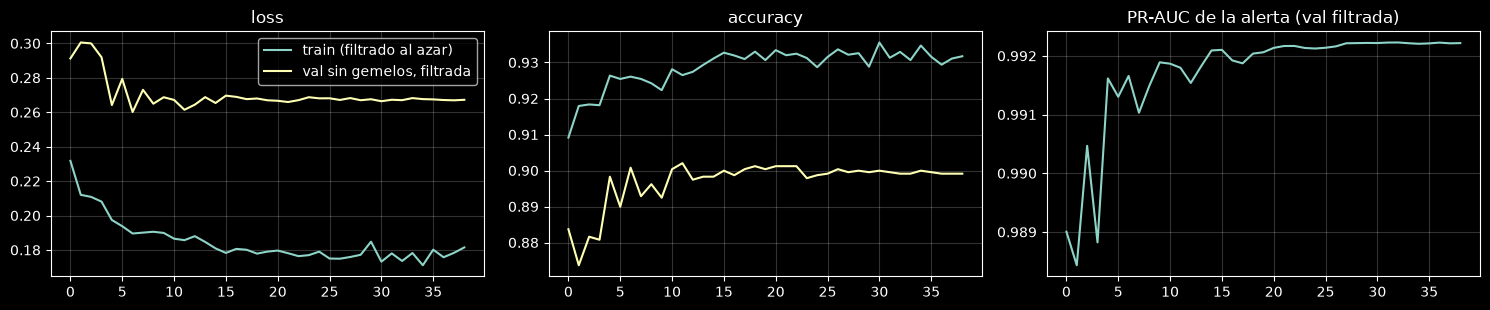

guardado: ../salidas/modelos/v4/20261019-1635/cnn_fuego_3clases_cam_epochs_39_image_size_320x240.keras


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, k in zip(axes, ["loss", "accuracy"]):
    ax.plot(historia[k], label="train (filtrado al azar)")
    ax.plot(historia["val_" + k], label="val sin gemelos, filtrada")
    ax.set_title(k)
axes[2].plot(historia["val_pr_auc"])
axes[2].set_title("PR-AUC de la alerta (val filtrada)")
for ax in axes:
    ax.grid(alpha=0.2)
axes[0].legend()
plt.tight_layout()
plt.savefig(CORRIDA / "curvas.png", dpi=120)
plt.show()

with open(CORRIDA / "historia.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["epoca", *historia])
    w.writerows([i, *fila] for i, fila in enumerate(zip(*historia.values())))
RUTA_NUEVO = CORRIDA / f"cnn_fuego_3clases_cam_epochs_{len(historia['loss'])}_image_size_{TAM[1]}x{TAM[0]}.keras"
modelo_base.save(RUTA_NUEVO)
print("guardado:", RUTA_NUEVO)

## 3. Base vs nuevo (float32)

Mismas imágenes para los dos modelos: D-Fire prueba sin gemelos **tal cual** (¿se olvidó algo?) y
**filtrada una vez** con semilla fija (¿mejoró sobre "imágenes tipo cámara"?). La alerta se mide
con el umbral del modelo base (`v3/cuantizacion/cuantizacion.json`) para los dos; el umbral
definitivo del modelo nuevo lo elige el notebook 5.

Si hay capturas ya etiquetadas (carpetas `normal/`, `humo/`, `incendio/` bajo
`DIR_CAPTURAS`, ver notebook 13), se suman: son la única medida sobre la cámara real.

In [7]:
u_base = json.loads((SALIDAS / "modelos" / f"v{VERSION_BASE}" / "cuantizacion" / "cuantizacion.json")
                    .read_text())["decision"]["umbral"]

test_ds = armar_ds(ARCHIVOS[test_limpio], CAT[test_limpio], BATCH_SIZE, tam=TAM)
tf.random.set_seed(SEED + 1)
filtro_test = CamaraOV(1.0)
test_cam_ds = test_ds.map(lambda x, y: (filtro_test(x, training=True), y)).cache()
for _ in test_cam_ds:      # fijo el filtrado: los dos modelos ven las mismas imágenes
    pass

conjuntos = [("D-Fire prueba sin gemelos", test_ds, CAT[test_limpio]),
             ("ídem filtrada (tipo cámara)", test_cam_ds, CAT[test_limpio])]
etiquetadas = [(p, c) for c, nombre in enumerate(CATEGORIAS)
               for p in sorted(DIR_CAPTURAS.rglob(f"{nombre}/*")) if p.suffix.lower() in (".bmp", ".jpg")]
if etiquetadas:
    rutas, y = map(np.array, zip(*[(str(p), c) for p, c in etiquetadas]))
    conjuntos.append(("capturas etiquetadas", armar_ds(rutas, y, BATCH_SIZE, tam=TAM), y))
else:
    print("(sin capturas etiquetadas: se mide sólo sobre D-Fire)\n")


def tasa(x):
    return np.mean(x) if len(x) else np.nan


for titulo, ds, y in conjuntos:
    print(f"== {titulo} ({len(y)} imágenes) ==")
    for nombre, modelo in [("base v3", modelo_ref), (f"nuevo v{VERSION}", modelo_base)]:
        prob = modelo.predict(ds, verbose=0)
        pred, alerta = prob.argmax(1), (1 - prob[:, 0]) >= u_base
        print(f"{nombre:<10} exactitud {np.mean(pred == y):.3f} | F1 macro "
              f"{f1_score(y, pred, labels=range(3), average='macro', zero_division=0):.3f} | "
              f"incendio sin alerta {tasa(~alerta[y == 2]):6.1%} | evento sin alerta "
              f"{tasa(~alerta[y > 0]):6.1%} | falsa alarma {tasa(alerta[y == 0]):6.1%}")
    print()

(sin capturas etiquetadas: se mide sólo sobre D-Fire)

== D-Fire prueba sin gemelos (3320 imágenes) ==
base v3    exactitud 0.931 | F1 macro 0.928 | incendio sin alerta   1.5% | evento sin alerta   5.3% | falsa alarma   2.3%
nuevo v4   exactitud 0.924 | F1 macro 0.921 | incendio sin alerta   1.4% | evento sin alerta   5.5% | falsa alarma   2.5%

== ídem filtrada (tipo cámara) (3320 imágenes) ==
base v3    exactitud 0.862 | F1 macro 0.860 | incendio sin alerta   7.0% | evento sin alerta  15.7% | falsa alarma   4.9%
nuevo v4   exactitud 0.909 | F1 macro 0.906 | incendio sin alerta   2.5% | evento sin alerta   7.7% | falsa alarma   3.9%



**Cómo leerlo.** Lo esperable: en la prueba **filtrada** el nuevo gana (menos incendios sin
alerta, menos falsas alarmas); en la prueba **tal cual** queda parecido o cae poco. Si en la
filtrada no gana, el filtro no está agregando nada que la red no supiera manejar y no vale la
pena seguir con v4. Si en la tal cual cae mucho, bajar `P_CAMARA`.

El número que decide es el de capturas reales con fuego, y todavía no existe: el filtro es una
aproximación medida sobre una sola escena.

## 4. Siguiente

1. `5_cuantizacion.ipynb` con `VERSION = 4`: toma `v4/<fecha-hora>/cnn_fuego_3clases_cam_*.keras`
   y deja `modelo_int8.cc/.tflite` y `cuantizacion.json` (con el umbral) en `v4/cuantizacion/`.
2. Llevar al nodo como dice la última celda del notebook 13 (carpeta en `modelo_cuantizacion/`,
   `CMakeLists.txt` y `UMBRAL_INT8`).
3. Con capturas etiquetadas: `13_fine_tuning_camara.ipynb` con `VERSION = 4`.